# Классификация зоопланктона на SYKE ZooScan 2024

По одному снимку с прибора ZooScan модель должна определить категорию объекта. Вода из проб Балтийского моря содержит как организмы, так и посторонние частицы, поэтому среди меток есть, например, `Bosmina_sp`, `Bubbles` и `Fibers_etc`. Рассматриваем задачу **закрытой классификации**: каждый пример на оценке принадлежит одному из выбранных классов.

Сравниваем **ResNet18 и EfficientNet-B0** с одним и тем же протоколом. В проверенном архиве Etsin **22 753 JPEG и 20 классов**. Из задачи исключаем пять категорий с менее чем 50 изображениями каждая. После проверки точных совпадений в оставшихся 15 классах получаем **13 511 Train, 4 522 Validation и 4 525 Test**. Идентификаторы проб недоступны в архиве, поэтому оцениваем качество на отложенных изображениях. Независимость выборок на уровне проб не установлена.

Классы сильно различаются по размеру. Поэтому основная метрика — **Macro F1**, среднее поклассовых F1 с одинаковым весом каждого класса. Так результат на редких категориях виден в общей оценке.


In [ ]:
import csv
import hashlib
import json
import math
import random
import time
from collections import Counter, defaultdict
from collections.abc import Iterable, Sequence
from contextlib import nullcontext
from pathlib import Path, PurePosixPath
from tempfile import mkdtemp
from typing import TypedDict
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from numpy.typing import NDArray
from PIL import Image
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from torch import nn
from torch.nn import functional
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

In [ ]:
SMOKE = False
# Set an explicit ZIP path or a directory with class_splits and images.
ARCHIVE: str | Path | None = None
SPLIT_SEED = 42
SEEDS = (42, 43, 44)
DATASET_ROOT = "SYKE-plankton_ZooScan_2024"
ARCHIVE_NAME = "SYKE-plankton_ZooScan_2024.zip"
SOURCE_URL = "https://etsin.fairdata.fi/dataset/6fa42787-9772-41a5-a6fc-0dde489ed908/data"
ARCHITECTURES = ("resnet18", "efficientnet_b0")
EXCLUDED = {"Eggs", "Fish_eggs", "Harpacticoida", "Mysis_sp", "Sessilia"}

device: torch.device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
if not SMOKE and device.type != "cuda":
    raise RuntimeError("Для полного обучения выбери GPU в настройках Kaggle.")
if device.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

kaggle_work_dir = Path("/kaggle/working")
work_dir = kaggle_work_dir if kaggle_work_dir.is_dir() else Path.cwd()
results_root = work_dir / "outputs" / ("smoke" if SMOKE else "full")
results_root.mkdir(parents=True, exist_ok=True)
output_dir = Path(mkdtemp(prefix="experiment_", dir=results_root))
learning_rates = (
    (1e-3,),
    (5e-4, 1e-4),
    (1e-4, 3e-5, 1e-5),
    (5e-5, 1e-5, 5e-6),
)
threshold = 0.0 if SMOKE else 0.95
N_RESAMPLES = 200 if SMOKE else 5_000
RESAMPLE_SEED = 2026
amp = device.type == "cuda"
image_size = 96 if SMOKE else 224
batch_size = 16 if SMOKE else 32
epochs = (1, 1, 1, 1) if SMOKE else (3, 5, 7, 5)
num_workers = 2 if device.type == "cuda" else 0

device_name = torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU"
print(f"Устройство: {device_name}")
print(f"Seeds обучения: {SEEDS}. Seed разбиения: {SPLIT_SEED}.")
print(f"Результаты будут в {output_dir}")

Сохранённый вывод полного запуска на Kaggle, до форматирования кода.
Устройство: Tesla T4
Seeds обучения: (42, 43, 44). Seed разбиения: 42.


In [ ]:
ImageRow = tuple[str, int]
PseudoRow = tuple[str, int, float]
HistoryRow = tuple[int, int, float, float, float]
Prediction = tuple[list[int], list[int], list[float], list[str]]
ImageBatch = tuple[torch.Tensor, int, float, str]
ModuleGroups = tuple[list[nn.Module], ...]
IntArray = NDArray[np.int64]
FloatArray = NDArray[np.float64]
MetricRow = tuple[
    int,
    str,
    float,
    float,
    float,
    bool,
    int,
    float,
    float,
    float | None,
    float | None,
    float | None,
]


class TrainingResult(TypedDict):
    supervised: Path
    final: Path
    accepted: int
    seconds: float

## Два примера из обучающей части

На оригиналах видна подпись и масштабная линейка. Справа — те же изображения после маскирования легенды, дополнения до квадрата и изменения размера. Переход к квадрату сохраняет пропорции объекта. Серия показывает, что у классов различаются форма тела и выраженность тонких придатков, которые важно сохранить при обработке.

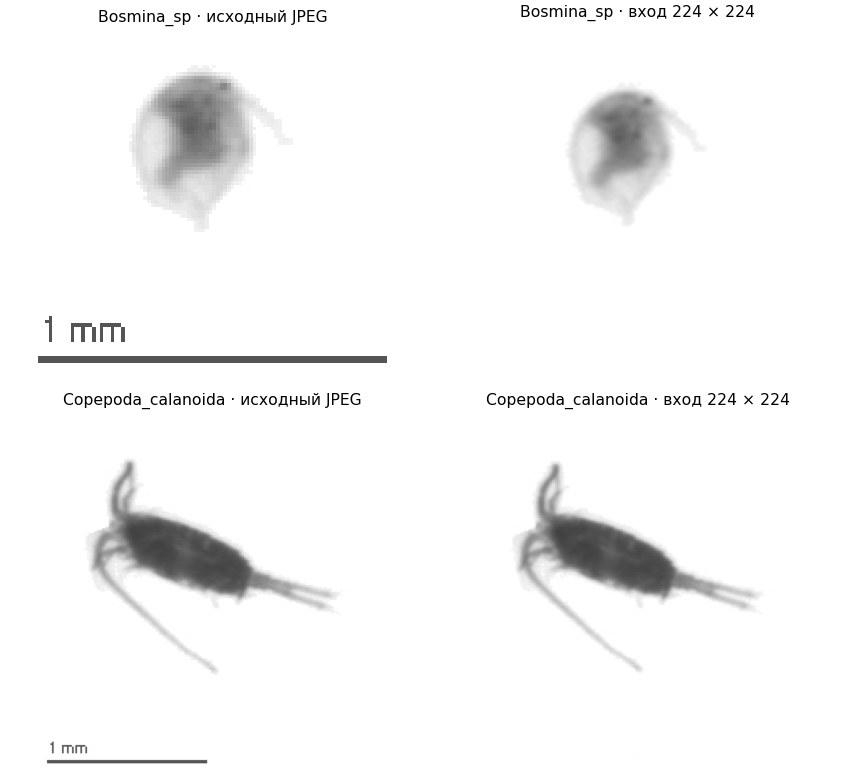

Файлы из архива Etsin: `Bosmina_sp_0773.jpg` и `Copepoda_calanoida_0803.jpg`.

## План эксперимента

| Шаг | Что делаем |
|---|---|
| Подготовка | Берём авторские Train, Validation и Test. Внутри Train оставляем 60% меток видимыми и скрываем 40%. Обе модели получают одинаковые части. |
| Supervised-обучение | Обучаем голову 3 эпохи, размораживаем верхний блок на 5 эпох, затем добавляем ещё один блок на 7 эпох. Аугментацию усиливаем по стадиям. |
| Псевдометки | Выбираем лучший checkpoint последней supervised-стадии на Validation, присваиваем уверенные псевдометки скрытой части Train и дообучаем до 5 эпох по общему расписанию. |
| Оценка | После выбора checkpoint прогоняем обе модели по одному Test. Сравниваем Macro F1, F1 по классам и матрицы ошибок. Для каждого прогона фиксируем долю принятых псевдометок и время. |

## Почему эти техники подходят

**Постепенное усиление аугментации.** Объект в пробе может находиться в кадре под разными углами, а контраст снимков может различаться. На первой стадии используем отражения, затем добавляем повороты на 90°, 180° и 270°, после чего усиливаем повороты и добавляем небольшое изменение контраста. Кратные 90° повороты квадратного кадра сохраняют его границы и не обрезают тонкие части объекта.

**Поэтапная разморозка с разными learning rate.** Новая голова должна научиться различать 15 категорий ZooScan. Верхние блоки затем адаптируются к монохромным снимкам и признакам организмов. Меньший learning rate в более ранних размороженных блоках ограничивает размер обновления предобученных весов.

**Псевдолейблинг.** Скрытые изображения взяты из того же Train и дают модели дополнительные варианты объектов. Teacher принимает предсказания с максимальным softmax score от 0.95, а лимит по предсказанному классу сдерживает размер пула для распространённых категорий. В функции потерь вклад псевдометок умножается на 0.25, поскольку уверенные предсказания тоже могут быть ошибочными. Если порог никто не проходит, остаётся supervised-модель.

Обе архитектуры используют все три техники, поэтому эксперимент сравнивает архитектуры при общем протоколе. Разницу до и после псевдолейблинга трактуем как изменение за всю стадию дообучения, включая дополнительные шаги оптимизации.

Источник данных — [архив Fairdata Etsin](https://etsin.fairdata.fi/dataset/6fa42787-9772-41a5-a6fc-0dde489ed908/data), CC BY 4.0. Описание датасета — [Kareinen и соавторы, Open-Set Plankton Recognition](https://arxiv.org/abs/2503.11318).

# 1. Открываем авторское разбиение

Читаем данные из ZIP или из распакованной папки Kaggle. Используем только JPEG из каталога данных и соответствующий `splits.json`. Точные совпадения файлов в пределах класса схлопываются с приоритетом Test, затем Validation, затем Train. Если одинаковые байты размечены разными классами, исключаем конфликтующую группу. Номер в названии JPEG не использован как идентификатор исходной пробы.

In [ ]:
def read_data(
    data_path: Path, archive: ZipFile | None, relative_path: Path
) -> bytes:
    if archive is None:
        return (data_path / relative_path).read_bytes()
    return archive.read((Path(DATASET_ROOT) / relative_path).as_posix())


def per_class_sample(rows: Sequence[ImageRow], limit: int) -> list[ImageRow]:
    rng = random.Random(SPLIT_SEED)
    groups: dict[int, list[ImageRow]] = defaultdict(list)
    for row in rows:
        groups[row[1]].append(row)
    return [
        row
        for group in groups.values()
        for row in rng.sample(group, min(limit, len(group)))
    ]


def write_csv(
    path: Path, header: Sequence[str], rows: Iterable[Iterable[object]]
) -> None:
    with path.open("w", encoding="utf-8", newline="") as stream:
        writer = csv.writer(stream)
        writer.writerow(header)
        writer.writerows(rows)


print("Подготовка данных для всех прогонов.", flush=True)
split_path = Path("class_splits") / DATASET_ROOT / "splits.json"
images_path = Path("images") / DATASET_ROOT

if ARCHIVE is not None:
    data_path = Path(ARCHIVE)
else:
    input_dir = Path("/kaggle/input")
    extracted = sorted(
        {
            file.parents[2]
            for file in input_dir.rglob("splits.json")
            if file.parts[-3:] == split_path.parts
            and (file.parents[2] / images_path).is_dir()
        }
    )
    local_zip = Path("data/raw") / ARCHIVE_NAME
    archives = sorted(input_dir.rglob(ARCHIVE_NAME))
    candidates = extracted or (
        [local_zip] if local_zip.is_file() else archives
    )
    if len(candidates) != 1:
        raise FileNotFoundError(
            "Укажи в ARCHIVE путь к ZIP или к папке "
            "с class_splits/ и images/. "
            f"Найденные варианты: {candidates}"
        )
    data_path = candidates[0]

if not data_path.exists():
    raise FileNotFoundError(f"Путь недоступен: {data_path}")

is_directory = data_path.is_dir()
print(f"Источник данных ({'папка' if is_directory else 'ZIP'}): {data_path}")

image_dir = work_dir / "syke_images"
image_dir.mkdir(parents=True, exist_ok=True)
archive_digest = None

if not is_directory:
    with data_path.open("rb") as stream:
        archive_digest = hashlib.file_digest(stream, "sha256").hexdigest()

with nullcontext() if is_directory else ZipFile(data_path) as archive:
    split_bytes = read_data(data_path, archive, split_path)
    split_spec = json.loads(split_bytes)
    split_digest = hashlib.sha256(split_bytes).hexdigest()
    categories = split_spec["categories"]
    class_names = [
        categories[key]
        for key in sorted(categories, key=int)
        if categories[key] not in EXCLUDED
    ]
    class_ids = {name: idx for idx, name in enumerate(class_names)}

    rows_by_hash: dict[bytes, list[tuple[str, int, str]]] = defaultdict(list)
    seen: set[str] = set()

    for original_idx, parts in split_spec["images"].items():
        category = categories[original_idx]
        if category not in class_ids:
            continue

        for split, files in parts.items():
            for filename in files:
                if (
                    PurePosixPath(filename).name != filename
                    or filename in seen
                ):
                    raise ValueError(
                        "Некорректное или повторное имя "
                        f"в splits.json: {filename}"
                    )
                seen.add(filename)
                payload = read_data(
                    data_path, archive, images_path / category / filename
                )
                (image_dir / filename).write_bytes(payload)
                digest = hashlib.sha256(payload).digest()
                rows_by_hash[digest].append(
                    (filename, class_ids[category], split)
                )

priority = {"test": 0, "valid": 1, "train": 2}
# Keep held-out copies first so no identical image crosses splits.
splits: dict[str, list[ImageRow]] = {split: [] for split in priority}
duplicates = 0
conflicts = 0

for rows in rows_by_hash.values():
    if len({row[1] for row in rows}) > 1:
        conflicts += len(rows)
        continue

    filename, label, split = min(
        rows, key=lambda row: (priority[row[2]], row[0])
    )
    splits[split].append((filename, label))
    duplicates += len(rows) - 1

for split, rows in splits.items():
    if {label for _, label in rows} != set(class_ids.values()):
        raise ValueError(f"В части {split} представлены не все классы.")
    print(split, len(rows))

print(f"Убрано точных копий: {duplicates}, конфликтующих записей: {conflicts}")

labeled, hidden = train_test_split(
    splits["train"],
    train_size=0.60,
    stratify=[label for _, label in splits["train"]],
    random_state=SPLIT_SEED,
)


if SMOKE:
    labeled = per_class_sample(labeled, 4)
    hidden = per_class_sample(hidden, 2)
    splits["valid"] = per_class_sample(splits["valid"], 2)
    splits["test"] = per_class_sample(splits["test"], 2)

unlabeled = [(filename, -1) for filename, _ in hidden]
del hidden, rows_by_hash
num_classes = len(class_names)


manifest = {
    "labeled": labeled,
    "unlabeled": unlabeled,
    "valid": splits["valid"],
    "test": splits["test"],
}

write_csv(
    output_dir / "splits.csv",
    ["split", "filename", "label"],
    (
        (part, filename, class_names[label] if label >= 0 else "")
        for part, rows in manifest.items()
        for filename, label in rows
    ),
)

(output_dir / "run.json").write_text(
    json.dumps(
        {
            "source": SOURCE_URL,
            "input_path": str(data_path),
            "archive_sha256": archive_digest,
            "splits_sha256": split_digest,
            "class_to_idx": class_ids,
            "seeds": SEEDS,
            "split_seed": SPLIT_SEED,
            "smoke": SMOKE,
            "epochs": epochs,
            "image_size": image_size,
            "batch_size": batch_size,
            "counts": {part: len(rows) for part, rows in manifest.items()},
            "duplicate_rows_removed": duplicates,
            "conflicting_rows_removed": conflicts,
            "torch": torch.__version__,
            "torchvision": torchvision.__version__,
            "device": device_name,
        },
        indent=2,
    ),
    encoding="utf-8",
)
print("Общее разбиение сохранено. Данные готовы.", flush=True)

Подготовка данных для всех прогонов.
Источник данных: распакованная папка в /kaggle/input
test 4525
valid 4522
train 13511
Убрано точных копий: 124, конфликтующих записей: 4
Общее разбиение сохранено. Данные готовы.


# 2. Предобработка и аугментация

В проверенных образцах линейка и подпись занимают узкую область у нижнего левого края. Маскируем эту область только при обнаружении характерной горизонтальной полосы. Контраст и повороты добавляем по стадиям. Для оценки и отбора псевдометок используется один детерминированный transform.

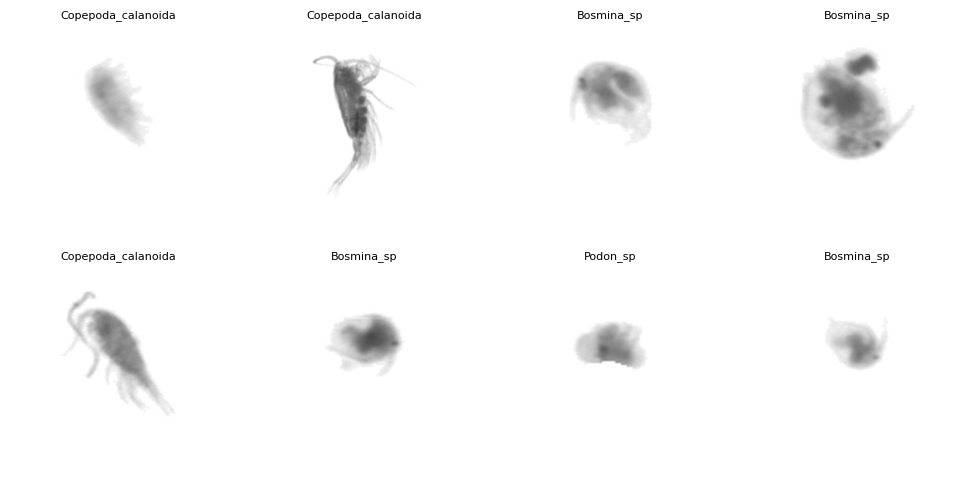

In [ ]:
def prepare_image(path: Path) -> Image.Image:
    with Image.open(path) as source:
        pixels = np.array(source.convert("RGB"))
    height, width = pixels.shape[:2]
    border = np.concatenate(
        (pixels[0], pixels[-1], pixels[:, 0], pixels[:, -1])
    )
    background = tuple(np.median(border, axis=0).astype(int).tolist())
    # Mask the annotation only when its dark horizontal scale bar is detected.
    if height >= 19 and width >= 105:
        scale_bar = pixels[-6:-4, 9:105]
        if (scale_bar.mean(axis=2) < 160).mean() > 0.95:
            pixels[-19:, : min(108, width)] = background
    side = max(height, width)
    canvas = Image.new("RGB", (side, side), background)
    canvas.paste(
        Image.fromarray(pixels), ((side - width) // 2, (side - height) // 2)
    )
    return canvas.resize((image_size, image_size), Image.Resampling.BICUBIC)


normalize = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
    ]
)
contrast = transforms.ColorJitter(contrast=0.1)
rotations = (
    Image.Transpose.ROTATE_90,
    Image.Transpose.ROTATE_180,
    Image.Transpose.ROTATE_270,
)


class PlanktonDataset(Dataset[ImageBatch]):
    def __init__(
        self, rows: Sequence[ImageRow | PseudoRow], stage: int = 0
    ) -> None:
        self.rows = rows
        self.stage = stage

    def __len__(self) -> int:
        return len(self.rows)

    def __getitem__(self, index: int) -> ImageBatch:
        filename, label, *pseudo_weight = self.rows[index]
        image = prepare_image(image_dir / filename)
        if self.stage and random.random() < 0.5:
            image = image.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
        if self.stage >= 2 and random.random() < (
            0.25 if self.stage == 2 else 0.5
        ):
            image = image.transpose(random.choice(rotations))
        if self.stage >= 3 and random.random() < 0.5:
            image = contrast(image)
        return (
            normalize(image),
            label,
            pseudo_weight[0] if pseudo_weight else -1.0,
            filename,
        )


def make_loader(
    rows: Sequence[ImageRow | PseudoRow], stage: int = 0
) -> DataLoader[ImageBatch]:
    return DataLoader(
        PlanktonDataset(rows, stage),
        batch_size=batch_size,
        shuffle=stage > 0,
        num_workers=num_workers,
        pin_memory=device.type == "cuda",
    )


fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax, (filename, label) in zip(
    axes.flat, random.Random(SPLIT_SEED).sample(labeled, 8)
):
    ax.imshow(prepare_image(image_dir / filename))
    ax.set_title(class_names[label], fontsize=8)
    ax.axis("off")
fig.tight_layout()
plt.show()
plt.close(fig)

# 3. Обучение двух моделей

Первые три стадии — разморозка и усиление аугментации. Лучший checkpoint третьей стадии становится teacher. На четвёртой стадии смешиваем исходные примеры и прошедшие отбор псевдометки. В smoke-режиме используем случайные веса и порог 0, чтобы проверить также ветку с псевдометками. Метрики smoke-прогона служат только для диагностики.

In [ ]:
counts = Counter(label for _, label in labeled)
class_weights: torch.Tensor = torch.tensor(
    [counts[label] ** -0.5 for label in range(num_classes)], device=device
)
all_class_ids = np.arange(num_classes)


def build_model(
    architecture: str, pretrained: bool
) -> tuple[nn.Module, ModuleGroups, list[nn.Module]]:
    if architecture == "resnet18":
        weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        model = models.resnet18(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        groups = ([model.fc], [model.layer4], [model.layer3])
        frozen = [model.bn1, model.layer1, model.layer2]
    else:
        weights = (
            models.EfficientNet_B0_Weights.IMAGENET1K_V1
            if pretrained
            else None
        )
        model = models.efficientnet_b0(weights=weights)
        model.classifier[-1] = nn.Linear(
            model.classifier[-1].in_features, num_classes
        )
        groups = (
            [model.classifier],
            list(model.features[7:9]),
            list(model.features[5:7]),
        )
        frozen = list(model.features[:5])
    return model.to(device), groups, frozen


@torch.inference_mode()
def predict(model: nn.Module, loader: DataLoader[ImageBatch]) -> Prediction:
    model.eval()
    targets: list[int] = []
    predictions: list[int] = []
    scores: list[float] = []
    filenames: list[str] = []
    for images, labels, _, names in loader:
        logits = model(images.to(device, non_blocking=amp))
        confidence, classes = logits.softmax(dim=1).max(dim=1)
        targets.extend(labels.tolist())
        predictions.extend(classes.tolist())
        scores.extend(confidence.tolist())
        filenames.extend(names)
    return targets, predictions, scores, filenames


def macro_f1(targets: Sequence[int], predictions: Sequence[int]) -> float:
    return f1_score(
        targets,
        predictions,
        labels=all_class_ids,
        average="macro",
        zero_division=0,
    )


def train_epoch(
    model: nn.Module,
    loader: DataLoader[ImageBatch],
    optimizer: torch.optim.Optimizer,
    scaler: torch.amp.GradScaler,
    frozen: Sequence[nn.Module],
) -> float:
    model.train()
    # Keep frozen BatchNorm statistics fixed after model.train().
    for block in frozen:
        block.eval()
    total_loss = 0.0
    for images, labels, confidence, _ in loader:
        images = images.to(device, non_blocking=amp)
        labels = labels.to(device, non_blocking=amp)
        confidence = confidence.to(
            device, dtype=torch.float32, non_blocking=amp
        )
        # Negative confidence marks samples with human annotations.
        supervised = confidence < 0
        pseudo = ~supervised
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=amp):
            logits = model(images)
            loss = logits.new_zeros(())
            if supervised.any():
                loss = functional.cross_entropy(
                    logits[supervised],
                    labels[supervised],
                    weight=class_weights,
                )
            if pseudo.any():
                per_image = functional.cross_entropy(
                    logits[pseudo], labels[pseudo], reduction="none"
                )
                loss = loss + 0.25 * (confidence[pseudo] * per_image).mean()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.detach().item()
    return total_loss / len(loader)


stage_names = (
    "голова",
    "разморозка верхнего блока",
    "разморозка следующего блока",
    "дообучение на псевдометках",
)


def fit_stage(
    model: nn.Module,
    groups: ModuleGroups,
    permanently_frozen: list[nn.Module],
    stage: int,
    rows: Sequence[ImageRow | PseudoRow],
    validation: DataLoader[ImageBatch],
    checkpoint: Path | None,
    history: list[HistoryRow],
    context: str,
) -> None:
    stage_rates = learning_rates[stage - 1]
    model.requires_grad_(False)
    parameter_groups = []
    for blocks, lr in zip(groups, stage_rates):
        for block in blocks:
            block.requires_grad_(True)
        parameter_groups.append(
            {
                "params": [p for block in blocks for p in block.parameters()],
                "lr": lr,
            }
        )
    frozen = permanently_frozen + [
        block for group in groups[len(stage_rates) :] for block in group
    ]
    optimizer = torch.optim.AdamW(parameter_groups, weight_decay=1e-4)
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    loader = make_loader(rows, stage=stage)
    best_f1 = -1.0
    stage_epochs = epochs[stage - 1]
    print(f"{context} · {stage_names[stage - 1]}", flush=True)
    for epoch in range(1, stage_epochs + 1):
        started = time.perf_counter()
        loss = train_epoch(model, loader, optimizer, scaler, frozen)
        targets, predictions, _, _ = predict(model, validation)
        score = macro_f1(targets, predictions)
        seconds = time.perf_counter() - started
        history.append((stage, epoch, loss, score, seconds))
        print(
            f"  Эпоха {epoch}/{stage_epochs} · loss {loss:.4f} · "
            f"Validation Macro F1 {score:.4f} · {seconds:.1f} с",
            flush=True,
        )
        if checkpoint is not None and score > best_f1:
            torch.save(model.state_dict(), checkpoint)
            best_f1 = score


def select_pseudo(model: nn.Module) -> list[PseudoRow]:
    _, classes, scores, names = predict(model, make_loader(unlabeled))
    accepted = []
    taken: Counter[int] = Counter()
    # Cap the most confident predictions within each predicted class.
    for confidence, filename, label in sorted(
        zip(scores, names, classes), key=lambda row: (-row[0], row[1])
    ):
        if confidence >= threshold and taken[label] < math.ceil(
            0.5 * counts[label]
        ):
            accepted.append((filename, label, confidence))
            taken[label] += 1
    return accepted


def save_learning_curves(
    history: Sequence[HistoryRow], path: Path, context: str
) -> None:
    fig, (loss_ax, score_ax) = plt.subplots(1, 2, figsize=(10, 4))
    stages, _, losses, scores, _ = zip(*history)
    steps = range(1, len(history) + 1)
    loss_ax.plot(steps, losses, "o-", markersize=3)
    score_ax.plot(steps, scores, "o-", markersize=3)
    loss_ax.set(xlabel="Эпоха", ylabel="Train loss")
    score_ax.set(xlabel="Эпоха", ylabel="Validation Macro F1")
    for index, (previous, current) in enumerate(
        zip(stages, stages[1:]), start=1
    ):
        if previous != current:
            for ax in (loss_ax, score_ax):
                ax.axvline(
                    index + 0.5, color="#555555", linestyle="--", alpha=0.6
                )
    fig.suptitle(context)
    fig.tight_layout()
    fig.savefig(path / "learning_curves.png", dpi=150)
    plt.close(fig)


def train_architecture(
    architecture: str, seed: int, seed_dir: Path, context: str
) -> TrainingResult:
    print(f"{context} · инициализация модели", flush=True)
    random.seed(seed)
    torch.manual_seed(seed)
    path = seed_dir / architecture
    path.mkdir(parents=True, exist_ok=True)
    supervised_path = path / "best_supervised.pt"
    semi_path = path / "best_semi_supervised.pt"
    model, groups, frozen = build_model(architecture, pretrained=not SMOKE)
    validation = make_loader(splits["valid"])
    history: list[HistoryRow] = []
    started = time.perf_counter()
    for stage in (1, 2, 3):
        fit_stage(
            model,
            groups,
            frozen,
            stage,
            labeled,
            validation,
            supervised_path if stage == 3 else None,
            history,
            context,
        )
    model.load_state_dict(
        torch.load(supervised_path, map_location=device, weights_only=True)
    )
    print(f"{context} · отбор псевдометок", flush=True)
    accepted = select_pseudo(model)
    write_csv(
        path / "pseudo_labels.csv",
        ["filename", "predicted_class", "confidence"],
        ((name, class_names[label], score) for name, label, score in accepted),
    )
    print(
        f"  Принято псевдометок: {len(accepted)} из {len(unlabeled)}",
        flush=True,
    )
    if accepted:
        fit_stage(
            model,
            groups,
            frozen,
            4,
            labeled + accepted,
            validation,
            semi_path,
            history,
            context,
        )
    else:
        print("  Стадия дообучения пропущена.", flush=True)
        semi_path.unlink(missing_ok=True)
    write_csv(
        path / "history.csv",
        ["stage", "epoch", "train_loss", "val_macro_f1", "seconds"],
        history,
    )
    seconds = time.perf_counter() - started
    save_learning_curves(history, path, context)
    return {
        "supervised": supervised_path,
        "final": semi_path if accepted else supervised_path,
        "accepted": len(accepted),
        "seconds": seconds,
    }

# 4. Финальная оценка

Test используется после фиксации всех checkpoint. Разность Macro F1 показывает изменение за всю стадию дообучения, включая дополнительные шаги оптимизации. `pseudo_ran=False` означает, что четвёртая стадия пропущена и итоговой осталась supervised-модель.

In [ ]:
MODEL_NAMES = {"resnet18": "ResNet18", "efficientnet_b0": "EfficientNet-B0"}
SCORE_COLUMNS = ("supervised_macro_f1", "final_macro_f1", "delta")
METRIC_COLUMNS = (
    "seed",
    "architecture",
    *SCORE_COLUMNS,
    "pseudo_ran",
    "pseudo_count",
    "pseudo_coverage",
    "train_seconds",
    "ci_95_low_pp",
    "ci_95_high_pp",
    "p_value",
)
comparison_path = output_dir / "comparison.csv"


def macro_f1_numpy(targets: IntArray, predictions: IntArray) -> float:
    matrix = np.bincount(
        num_classes * targets + predictions,
        minlength=num_classes**2,
    ).reshape(num_classes, num_classes)
    denominator = matrix.sum(axis=0) + matrix.sum(axis=1)
    scores = np.divide(
        2 * matrix.diagonal(),
        denominator,
        out=np.zeros(num_classes),
        where=denominator > 0,
    )
    return float(scores.mean())


def macro_f1_deltas(
    targets: IntArray, before: IntArray, after: IntArray
) -> FloatArray:
    return np.asarray(
        [
            macro_f1_numpy(targets, right) - macro_f1_numpy(targets, left)
            for left, right in zip(before, after)
        ]
    )


def paired_macro_f1_stats(
    targets: IntArray, before: IntArray, after: IntArray
) -> tuple[float, float, float]:
    # Rows are seeds. Columns align the same test images in both arrays.
    rng = np.random.default_rng(RESAMPLE_SEED)
    observed = macro_f1_deltas(targets, before, after).mean()
    by_class = [
        np.flatnonzero(targets == label) for label in np.unique(targets)
    ]
    bootstrap_deltas = np.empty(N_RESAMPLES)
    as_extreme = 0

    for i in range(N_RESAMPLES):
        sample = np.concatenate(
            [
                rng.choice(indices, size=len(indices), replace=True)
                for indices in by_class
            ]
        )
        bootstrap_deltas[i] = macro_f1_deltas(
            targets[sample], before[:, sample], after[:, sample]
        ).mean()

        # Share each test-image swap across all seeds.
        swap = rng.random(len(targets)) < 0.5
        perm_before = np.where(swap, after, before)
        perm_after = np.where(swap, before, after)
        perm_delta = macro_f1_deltas(targets, perm_before, perm_after).mean()
        as_extreme += abs(perm_delta) >= abs(observed) - 1e-12

    low, high = np.quantile(bootstrap_deltas, [0.025, 0.975])
    return float(low), float(high), float((as_extreme + 1) / (N_RESAMPLES + 1))


def evaluate_architecture(
    architecture: str,
    run: TrainingResult,
    seed: int,
    seed_dir: Path,
    test_loader: DataLoader[ImageBatch],
    context: str,
) -> MetricRow:
    print(f"{context} · оценка на Test и сохранение предсказаний", flush=True)
    model, _, _ = build_model(architecture, pretrained=False)
    model.load_state_dict(
        torch.load(run["supervised"], map_location=device, weights_only=True)
    )
    targets, supervised_predictions, _, filenames = predict(model, test_loader)
    supervised_score = macro_f1(targets, supervised_predictions)

    if run["accepted"]:
        model.load_state_dict(
            torch.load(run["final"], map_location=device, weights_only=True)
        )
        final_targets, final_predictions, _, final_filenames = predict(
            model, test_loader
        )
        if filenames != final_filenames or targets != final_targets:
            raise ValueError(
                "Предсказания до и после не совпадают по порядку изображений."
            )
    else:
        final_predictions = supervised_predictions

    final_score = macro_f1(targets, final_predictions)
    path = seed_dir / architecture

    write_csv(
        path / "test_predictions.csv",
        ["filename", "target", "pred_supervised", "pred_final"],
        zip(filenames, targets, supervised_predictions, final_predictions),
    )

    matrix = confusion_matrix(targets, final_predictions, labels=all_class_ids)
    by_class = f1_score(
        targets,
        final_predictions,
        labels=all_class_ids,
        average=None,
        zero_division=0,
    )
    write_csv(
        path / "per_class.csv",
        ["class", "support", "f1"],
        zip(class_names, matrix.sum(axis=1), by_class),
    )
    write_csv(
        path / "confusion_matrix.csv",
        ["true_class", *class_names],
        ((name, *row) for name, row in zip(class_names, matrix)),
    )

    fig, ax = plt.subplots(figsize=(10, 8))
    heatmap = ax.imshow(
        matrix / matrix.sum(axis=1, keepdims=True),
        vmin=0,
        vmax=1,
        cmap="Blues",
    )
    ax.set(
        xticks=all_class_ids,
        yticks=all_class_ids,
        yticklabels=class_names,
        xlabel="Предсказанный класс",
        ylabel="Истинный класс",
        title=architecture,
    )
    ax.set_xticklabels(class_names, rotation=65, ha="right")
    fig.colorbar(heatmap, ax=ax, label="Доля в истинном классе")
    fig.tight_layout()
    fig.savefig(path / "confusion_matrix.png", dpi=150)
    plt.close(fig)

    delta = final_score - supervised_score
    print(
        f"  Test Macro F1 {supervised_score:.4f} → {final_score:.4f} "
        f"({100 * delta:+.2f} п.п.)",
        flush=True,
    )
    low = high = p_value = None
    if run["accepted"]:
        print(f"{context} · парные статистические тесты", flush=True)
        low, high, p_value = paired_macro_f1_stats(
            np.asarray(targets, dtype=np.int64),
            np.asarray([supervised_predictions], dtype=np.int64),
            np.asarray([final_predictions], dtype=np.int64),
        )
        print(
            f"  95% ДИ [{100 * low:+.2f}, {100 * high:+.2f}] п.п. · "
            f"p = {p_value:.4f}",
            flush=True,
        )

    return (
        seed,
        architecture,
        supervised_score,
        final_score,
        delta,
        bool(run["accepted"]),
        run["accepted"],
        run["accepted"] / len(unlabeled),
        run["seconds"],
        None if low is None else 100 * low,
        None if high is None else 100 * high,
        p_value,
    )


def read_csv(path: Path) -> list[dict[str, str]]:
    with path.open(encoding="utf-8", newline="") as stream:
        return list(csv.DictReader(stream))


def append_seed_results(rows: Sequence[MetricRow]) -> None:
    needs_header = not comparison_path.exists()
    with comparison_path.open("a", encoding="utf-8", newline="") as stream:
        writer = csv.writer(stream)
        if needs_header:
            writer.writerow(METRIC_COLUMNS)
        writer.writerows(rows)

In [ ]:
# Reuse completed seeds when rerunning this cell within the same session.
completed: dict[int, list[str]] = {}
if comparison_path.exists():
    for row in read_csv(comparison_path):
        completed.setdefault(int(row["seed"]), []).append(row["architecture"])
    for seed, architectures in completed.items():
        if seed not in SEEDS or sorted(architectures) != sorted(ARCHITECTURES):
            raise ValueError(
                f"В {comparison_path} неполные или повторные "
                f"строки для seed {seed}."
            )

test_loader = make_loader(splits["test"])
for i, seed in enumerate(SEEDS, start=1):
    progress = f"Прогон {i}/{len(SEEDS)} · seed {seed}"
    if seed in completed:
        print(f"{progress} · результаты уже сохранены", flush=True)
        continue
    seed_dir = output_dir / f"seed_{seed}"
    seed_results: list[MetricRow] = []
    for architecture in ARCHITECTURES:
        context = f"{progress} · {MODEL_NAMES[architecture]}"
        run = train_architecture(architecture, seed, seed_dir, context)
        seed_results.append(
            evaluate_architecture(
                architecture, run, seed, seed_dir, test_loader, context
            )
        )
    append_seed_results(seed_results)
    print(
        f"{progress} · в comparison.csv добавлено строк: {len(seed_results)}",
        flush=True,
    )

Полный запуск на Kaggle · Test Macro F1 до и после дообучения
seed 42 · ResNet18 · 0.9367 → 0.9316 (-0.51 п.п.)
seed 42 · EfficientNet-B0 · 0.9139 → 0.9210 (+0.71 п.п.)
seed 43 · ResNet18 · 0.9455 → 0.9426 (-0.30 п.п.)
seed 43 · EfficientNet-B0 · 0.9084 → 0.9249 (+1.64 п.п.)
seed 44 · ResNet18 · 0.9414 → 0.9337 (-0.77 п.п.)
seed 44 · EfficientNet-B0 · 0.9114 → 0.9272 (+1.59 п.п.)


In [ ]:
def prediction_arrays(
    rows: Sequence[dict[str, str]],
) -> tuple[IntArray, dict[tuple[int, str], dict[str, IntArray]]]:
    predictions: dict[tuple[int, str], dict[str, IntArray]] = {}
    reference = None
    for row in rows:
        key = (int(row["seed"]), row["architecture"])
        path = output_dir / f"seed_{key[0]}" / key[1] / "test_predictions.csv"
        records = read_csv(path)
        test_examples = [
            (record["filename"], int(record["target"])) for record in records
        ]
        if reference is None:
            reference = test_examples
        elif test_examples != reference:
            raise ValueError(
                "Список или истинные метки тестовых изображений "
                "различаются между прогонами."
            )
        predictions[key] = {
            field: np.array(
                [int(record[field]) for record in records], dtype=np.int64
            )
            for field in ("pred_supervised", "pred_final")
        }
    if reference is None:
        raise ValueError("Нет сохранённых тестовых предсказаний.")
    targets = np.array([target for _, target in reference], dtype=np.int64)
    return targets, predictions


def holm_adjust(p_values: Sequence[float]) -> FloatArray:
    # Cumulative maxima keep adjusted p-values ordered by the raw values.
    order = np.argsort(p_values)
    adjusted = np.empty(len(p_values))
    adjusted[order] = np.minimum(
        1.0,
        np.maximum.accumulate(
            np.asarray(p_values)[order]
            * (len(p_values) - np.arange(len(p_values)))
        ),
    )
    return adjusted


def summarize_experiment(rows: Sequence[dict[str, str]]) -> None:
    by_model: dict[str, list[dict[str, str]]] = {
        architecture: [] for architecture in ARCHITECTURES
    }
    for row in rows:
        by_model[row["architecture"]].append(row)
    for model_rows in by_model.values():
        model_rows.sort(key=lambda row: int(row["seed"]))

    seed_summary = []
    scores = {}
    for architecture, model_rows in by_model.items():
        values = np.array(
            [
                [float(row[column]) for column in SCORE_COLUMNS]
                for row in model_rows
            ]
        )
        scores[architecture] = values
        mean = values.mean(axis=0)
        sd = values.std(axis=0, ddof=1)
        seed_summary.append(
            (
                architecture,
                len(values),
                mean[0],
                sd[0],
                mean[1],
                sd[1],
                100 * mean[2],
                100 * sd[2],
            )
        )
        print(
            f"{MODEL_NAMES[architecture]} · Macro F1 "
            f"до {mean[0]:.4f} ± {sd[0]:.4f}, "
            f"после {mean[1]:.4f} ± {sd[1]:.4f} · "
            f"Δ {100 * mean[2]:+.2f} ± {100 * sd[2]:.2f} п.п.",
            flush=True,
        )

    write_csv(
        output_dir / "seed_summary.csv",
        [
            "architecture",
            "n_seeds",
            "supervised_mean",
            "supervised_sd",
            "final_mean",
            "final_sd",
            "delta_mean_pp",
            "delta_sd_pp",
        ],
        seed_summary,
    )

    fig, ax = plt.subplots(figsize=(9, 5))
    for architecture, values in scores.items():
        (line,) = ax.plot(
            [0, 1],
            values[:, :2].mean(axis=0),
            "o-",
            linewidth=3,
            label=MODEL_NAMES[architecture],
        )
        for seed_scores in values:
            ax.plot(
                [0, 1],
                seed_scores[:2],
                "o-",
                color=line.get_color(),
                alpha=0.3,
            )
    ax.set(
        xticks=[0, 1],
        xticklabels=["До дообучения", "После дообучения"],
        ylabel="Test Macro F1",
        title="Macro F1 по seed и среднее",
    )
    ax.legend()
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    fig.savefig(output_dir / "macro_f1_by_seed.png", dpi=150)
    plt.show()
    plt.close(fig)


def compare_experiment(rows: Sequence[dict[str, str]]) -> None:
    targets, predictions = prediction_arrays(rows)
    comparisons = (
        (
            "resnet18_pseudo",
            "ResNet18 · эффект дообучения",
            ("resnet18", "pred_supervised"),
            ("resnet18", "pred_final"),
        ),
        (
            "efficientnet_b0_pseudo",
            "EfficientNet-B0 · эффект дообучения",
            ("efficientnet_b0", "pred_supervised"),
            ("efficientnet_b0", "pred_final"),
        ),
        (
            "final_architectures",
            "Финальная ResNet18 − EfficientNet-B0",
            ("efficientnet_b0", "pred_final"),
            ("resnet18", "pred_final"),
        ),
    )
    aggregate = []
    for key, label, (model_a, field_a), (model_b, field_b) in comparisons:
        print(f"Парные тесты по общему Test · {label}", flush=True)
        before = np.stack(
            [predictions[(seed, model_a)][field_a] for seed in SEEDS]
        )
        after = np.stack(
            [predictions[(seed, model_b)][field_b] for seed in SEEDS]
        )
        low, high, p_value = paired_macro_f1_stats(targets, before, after)
        deltas = 100 * macro_f1_deltas(targets, before, after)
        aggregate.append(
            (
                key,
                label,
                deltas.mean(),
                deltas.std(ddof=1),
                100 * low,
                100 * high,
                p_value,
            )
        )

    adjusted = holm_adjust([row[-1] for row in aggregate])
    write_csv(
        output_dir / "aggregate_tests.csv",
        [
            "comparison",
            "label",
            "delta_mean_pp",
            "delta_sd_across_seeds_pp",
            "ci_95_low_pp",
            "ci_95_high_pp",
            "p_value",
            "p_value_holm",
        ],
        ((*row, p_adj) for row, p_adj in zip(aggregate, adjusted)),
    )

    conclusions = [
        "95% ДИ по тестовым изображениям при фиксированных моделях. "
        "Перестановочные p-value скорректированы методом Холма "
        "для трёх итоговых сравнений. "
        "Разброс по seed показан отдельно."
    ]
    if SMOKE:
        conclusions.insert(
            0,
            "Диагностический прогон на подвыборке. "
            "Цифры только для проверки кода.",
        )
    for (_, label, delta, sd, low, high, _), p_adj in zip(aggregate, adjusted):
        if p_adj < 0.05 and (low > 0 or high < 0):
            interpretation = "обнаружена статистически значимая разница"
        elif p_adj >= 0.05:
            interpretation = (
                "статистически значимая разница после поправки "
                "Холма не обнаружена"
            )
        else:
            interpretation = (
                "тест после поправки Холма значим, 95% ДИ включает ноль"
            )
        conclusions.append(
            f"{label}\n"
            f"Δ {delta:+.2f} п.п., SD по seed {sd:.2f} п.п., "
            f"95% ДИ [{low:+.2f}, {high:+.2f}], p (Холм) = {p_adj:.4f}. "
            f"{interpretation}."
        )

    skipped = [
        f"{MODEL_NAMES[row['architecture']]}, seed {row['seed']}"
        for row in rows
        if row["pseudo_ran"] == "False"
    ]
    if skipped:
        conclusions.append(
            "Дообучение пропущено при пустом отборе: "
            + "; ".join(skipped)
            + ". В сравнении учитывается итоговый чекпойнт каждого прогона."
        )
    conclusions.append(
        "Разница до и после относится ко всей стадии дообучения. "
        "Проверка предполагает независимость тестовых изображений. "
        "Три seed дают описательную оценку разброса между запусками."
    )
    conclusion_text = "\n\n".join(conclusions)
    (output_dir / "conclusions.txt").write_text(
        conclusion_text + "\n", encoding="utf-8"
    )
    print(conclusion_text, flush=True)

    fig, ax = plt.subplots(figsize=(9, 4))
    positions = np.arange(len(aggregate))
    for i, (_, _, delta, _, low, high, _) in enumerate(aggregate):
        ax.hlines(i, low, high, linewidth=2.5, color="#185A93")
        ax.plot(delta, i, "o", color="#123962")
    ax.axvline(0, color="#333333", linestyle="--")
    ax.set(
        yticks=positions,
        yticklabels=[row[1] for row in aggregate],
        xlabel="Разница Macro F1, п.п.",
        title="Средние разницы и 95% bootstrap-интервалы",
    )
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    fig.savefig(output_dir / "paired_macro_f1_intervals.png", dpi=150)
    plt.show()
    plt.close(fig)

Сводка по seed · среднее ± стандартное отклонение
ResNet18 · Macro F1 до 0.9412 ± 0.0044, после 0.9360 ± 0.0058 · Δ -0.53 ± 0.24 п.п.
EfficientNet-B0 · Macro F1 до 0.9113 ± 0.0027, после 0.9244 ± 0.0031 · Δ +1.31 ± 0.52 п.п.


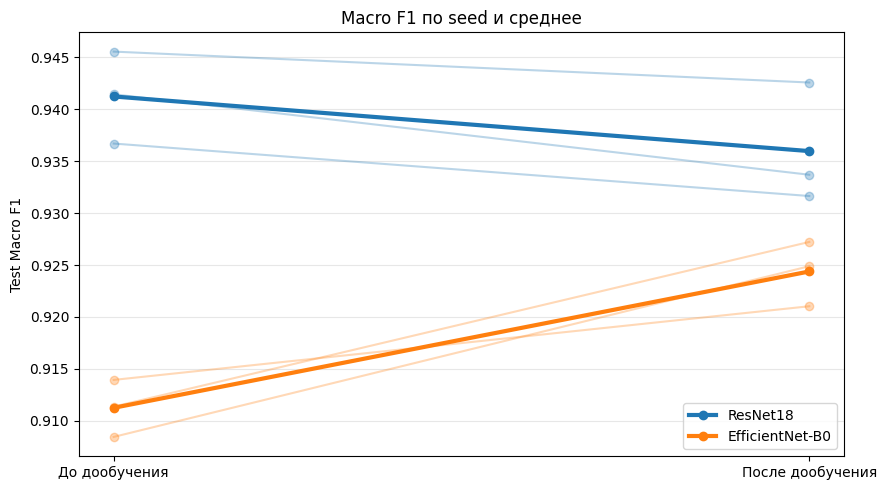

Парные тесты по общему Test · ResNet18 · эффект дообучения
Парные тесты по общему Test · EfficientNet-B0 · эффект дообучения
Парные тесты по общему Test · Финальная ResNet18 − EfficientNet-B0
95% ДИ по тестовым изображениям при фиксированных моделях. Перестановочные p-value скорректированы методом Холма для трёх итоговых сравнений. Разброс по seed показан отдельно.

ResNet18 · эффект дообучения
Δ -0.53 п.п., SD по seed 0.24 п.п., 95% ДИ [-1.25, +0.17], p (Холм) = 0.2999. статистически значимая разница после поправки Холма не обнаружена.

EfficientNet-B0 · эффект дообучения
Δ +1.31 п.п., SD по seed 0.52 п.п., 95% ДИ [+0.62, +1.97], p (Холм) = 0.0006. обнаружена статистически значимая разница.

Финальная ResNet18 − EfficientNet-B0
Δ +1.16 п.п., SD по seed 0.57 п.п., 95% ДИ [-0.33, +2.73], p (Холм) = 0.2999. статистически значимая разница после поправки Холма не обнаружена.

Разница до и после относится ко всей стадии дообучения. Проверка предполагает независимость тестовых изображений. Т

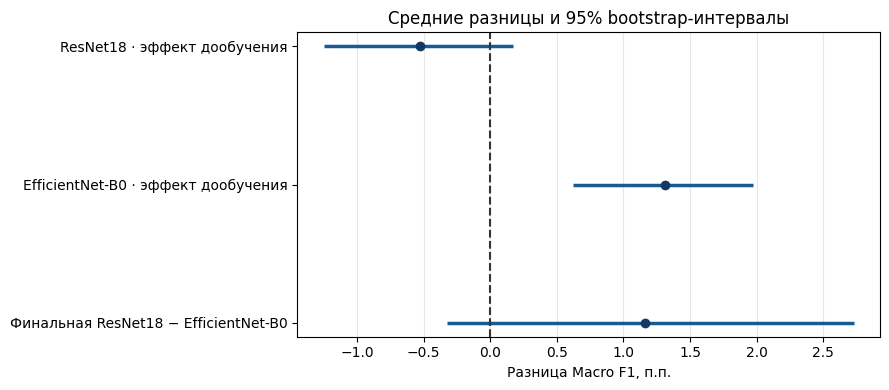

In [ ]:
metrics = read_csv(comparison_path)
print("\nСводка по seed · среднее ± стандартное отклонение", flush=True)
summarize_experiment(metrics)
compare_experiment(metrics)
print(f"Эксперимент завершён. Результаты: {output_dir}", flush=True)